<a href="https://colab.research.google.com/github/gashammamedgasanov-ux/Lab1Statistics-/blob/main/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%D1%81%D1%82%D0%B0%D1%82%D0%B8%D1%81%D1%82%D0%B8%D0%BA%D0%B0_%D1%81%D0%BF%D1%80%D0%B8%D0%BD%D1%821_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Лабораторная работа №1**
**Команда**: ic22

**Члены команды:** Мамедгасанов Гашам, Дрожжина Анна, Михайлова Мария (Инфохимия) Караева Станислава, Котикова Елизавета (Дизайн)

**Цель работы:** освоить полный цикл статистического анализа и стохастического
моделирования реальных физико-химических данных на примере датасета ESOL
(Delaney, 2004) о водной растворимости органических соединений.

**Задачи по спринтам**

**Спринт 1 — статистический анализ**

1. **Описать данные.** Провести разведочный анализ (EDA) трёх случайных
   величин — `LogS` (растворимость), `MW` (молекулярная масса), `TPSA`
   (полярная площадь поверхности) — и всего датасета целиком.
2. **Обосновать стохастичность.** Показать, что каждая величина является
   случайной, а не детерминированной: привести физико-химические и
   экспериментальные причины вариабельности.
3. **Подобрать распределения.** Сопоставить эмпирические распределения
   с теоретическими законами (нормальный, логнормальный, экспоненциальный,
   гамма) и проверить согласие статистическими тестами.
4. **Проверить гипотезы.** Сформулировать и проверить статистические
   гипотезы о нормальности, о различии групп (лёгкие/тяжёлые молекулы,
   полярные/неполярные) и о согласии с теоретическим законом.
5. **Оценить зависимости.** Проверить корреляции между величинами
   (Пирсон и Спирмен) и воспроизвести ключевой вывод оригинальной
   статьи Delaney (2004): молекулярная масса — главный предиктор
   растворимости.
6. **Исследовать оценки.** Эмпирически показать состоятельность
   выборочных оценок среднего и дисперсии, сравнить выборки
   с возвращением и без.

 **Спринт 2 — генерация случайных чисел**

1. **Разработать собственный ГСЧ.** Реализовать генератор случайных чисел
   для `LogS` без использования встроенных функций целевых распределений,
   опираясь только на базовый равномерный датчик «Вихрь Мерсенна».
2. **Освоить два алгоритма.** Реализовать метод полярных координат
   Марсальи (для нормального закона) и метод обратной функции
   (для логистического закона).
3. **Проверить генератор.** Написать автотесты и сравнить статистики
   синтетических выборок с реальными данными.
4. **Обосновать выбор.** Провести аналитический обзор 8 алгоритмов
   датчиков случайных чисел с опорой на академическую литературу.




# Описание и источник датасета
**Название:** ESOL (Delaney) — Delaney Solubility Dataset  
**Источник:** [DeepChem, `delaney-processed.csv`](https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv)  
**Первоисточник:** Delaney J. S. *ESOL: Estimating Aqueous Solubility Directly
from Molecular Structure* // Journal of Chemical Information and Computer
Sciences (ACS). — 2004. — Vol. 44, No. 3. — P. 1000–1005.  
**Объём:** 1128 органических соединений.

Датасет собран для задачи предсказания водной растворимости по структуре
молекулы. Каждая строка — одно соединение; для него известны:

| Колонка | Смысл | Единицы |
|---|---|---|
| `Compound ID` | Идентификатор соединения | — |
| `measured log solubility in mols per litre` | Экспериментальная растворимость (LogS) | log₁₀(моль/л) |
| `Molecular Weight` | Молекулярная масса (MW) | г/моль |
| `Polar Surface Area` | Топологическая полярная площадь (TPSA) | Å² |
| `Number of H-Bond Donors` | Доноры водородной связи | шт. |
| `Number of H-Bond Acceptors` | Акцепторы водородной связи | шт. |
| `Number of Rotatable Bonds` | Вращающиеся связи | шт. |
| `smiles` | SMILES-строка структуры | — |

# Рассматрваемые случайные величины

В данной работе мы рассматрим следующие случайные величины, представленные в датасете: **`LogS`**, **`MW`**, **`TPSA`** (переименованы в `data` после загрузки).

Описание случайных величин:

1. `LogS` — десятичный логарифм водной растворимости:
$\text{LogS} = \log_{10} S$, где $S$ — равновесная концентрация
насыщенного раствора в моль/л при 25 °C. (измерено экспериментально методом «встряхивания флакона»
  (shake-flask) с последующим определением концентрации методами ВЭЖХ
  или УФ-спектрофотометрии)
2. `MW` (Molecular Weight) — молекулярная масса: сумма атомных
масс всех элементов в брутто-формуле молекулы.Рассчитывается по структуре молекулы (SMILES)
суммированием стандартных атомных масс. Для индивидуального вещества
это детерминированная величина, но в рамках датасета — случайная,
потому что молекула выбирается случайно.
3. `TPSA` (Topological Polar Surface Area) — топологическая
полярная площадь поверхности: суммарная площадь полярных атомов
молекулы (кислород, азот и связанные с ними атомы водорода).



# Загрузка необходимых библиотек и вывод первых 6 строк датасета с выбранными случайными величинами

In [1]:
import io
import requests
import urllib3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

url = "https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv"
response = requests.get(url, verify=False)
df = pd.read_csv(io.StringIO(response.text))

data = df[[
    'measured log solubility in mols per litre',
    'Molecular Weight',
    'Polar Surface Area'
]].copy()

data.columns = ['LogS', 'MW', 'TPSA']

data.head()

,LogS,MW,TPSA
0,-0.77,457.432,202.32
1,-3.30,201.225,42.24
2,-2.06,152.237,17.07
3,-7.87,278.354,0.00
4,-1.33,84.143,0.00


# Random Variable 1
### **LogS — Десятичный логарифм водной растворимости**

### Описание

**Физико-химический смысл:** Величина `LogS` ($\log_{10} S$, где $S$ выражена в моль/л) отражает экспериментально измеренную равновесную растворимость низкомолекулярных органических соединений в воде при стандартной температуре $25^\circ\text{C}$.

**Доказательство стохастической природы данных (почему значение нельзя вычислить детерминированно формулой):**
1. **Термодинамический и квантово-химический фактор:** Растворение вещества в воде (сольватация) складывается из разрушения кристаллической решетки твердого вещества, образования полости в сетке водородных связей воды и межмолекулярного взаимодействия «вещество — растворитель». Из-за теплового хаотического движения молекул, конформационной гибкости цепочек и энтропийных эффектов не существует точной аналитической детерминированной формулы, позволяющей безошибочно вычислить растворимость произвольной молекулы.
2. **Инструментальный и экспериментальный фактор:** Значения в базе данных ESOL получены в разных лабораториях классическим методом встряхивания флакона (*Shake-Flask method*) с последующим определением концентрации методами ВЭЖХ или УФ-спектрофотометрии. Микроколебания температуры термостата, степень чистоты растворителя, полиморфизм осадков и случайный электронный шум детекторов создают неизбежную стохастическую погрешность измерения.

,Статистическая метрика,Значение
0,Объем выборки (N),1128.0000
1,Пропущенные значения (NaN),0.0000
2,Среднее арифметическое (Mean),-3.0501
3,Медиана (Median),-2.8600
4,Мода (Mode),-1.9600
5,Дисперсия (Variance),4.3951
6,Среднеквадратическое отклонение (Std),2.0964
7,Минимум (Min),-11.6000
8,Квантиль 25% (Q1),-4.3175
9,Квантиль 75% (Q3),-1.6000


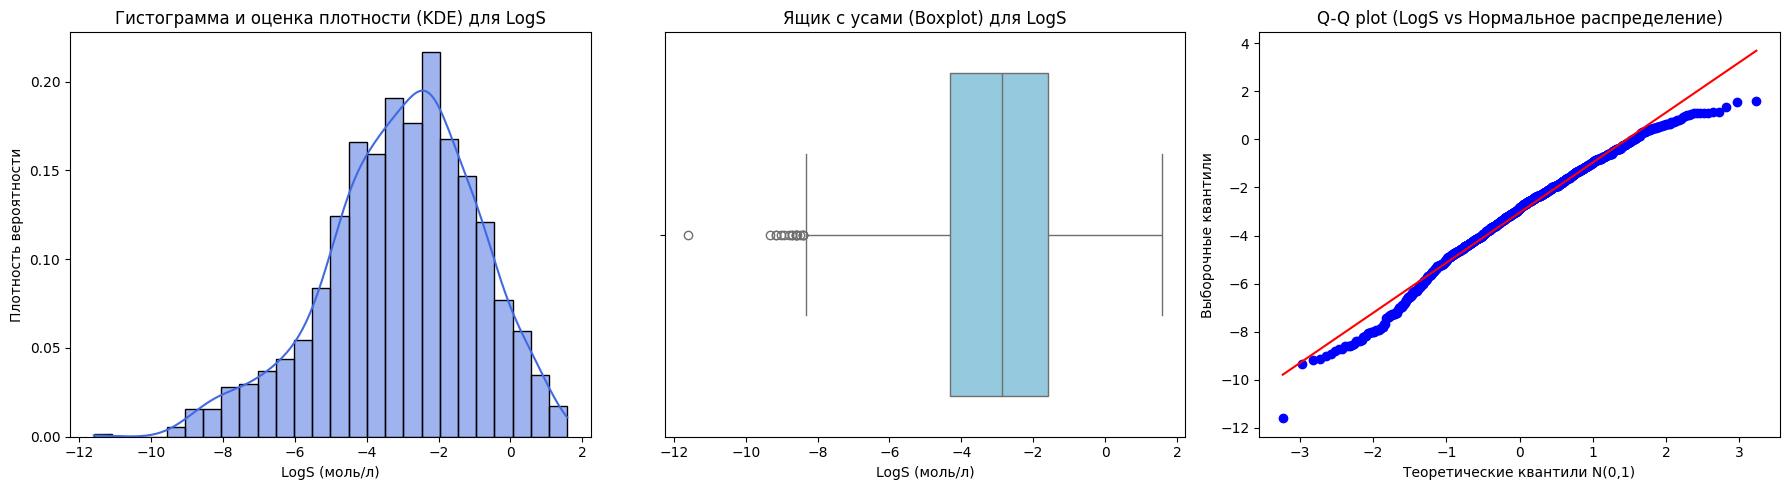

Проверка Z-стандартизации LogS: Mean = -0.0000, Std = 1.0000
Проверка Min-Max нормализации LogS: Min = 0.0000, Max = 1.0000


In [2]:
def perform_eda(series, name, unit):
    """Универсальная функция для расчета всех статистик и построения графиков EDA."""
    # 1. Расчет статистик
    q25, q75 = series.quantile(0.25), series.quantile(0.75)
    stats_df = pd.DataFrame({
        'Статистическая метрика': [
            'Объем выборки (N)', 'Пропущенные значения (NaN)',
            'Среднее арифметическое (Mean)', 'Медиана (Median)', 'Мода (Mode)',
            'Дисперсия (Variance)', 'Среднеквадратическое отклонение (Std)',
            'Минимум (Min)', 'Квантиль 25% (Q1)', 'Квантиль 75% (Q3)', 'Максимум (Max)',
            'Межквартильный размах (IQR)', 'Коэффициент асимметрии (Skewness)', 'Эксцесс (Kurtosis)'
        ],
        'Значение': [
            series.count(), series.isna().sum(),
            series.mean(), series.median(), series.mode().iloc[0],
            series.var(), series.std(),
            series.min(), q25, q75, series.max(),
            q75 - q25, series.skew(), series.kurtosis()
        ]
    })
    display(stats_df.round(4))

    # 2. Визуализация: Гистограмма + KDE, Boxplot, Q-Q plot
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sns.histplot(series, kde=True, stat="density", ax=axes[0], color='royalblue')
    axes[0].set_title(f'Гистограмма и оценка плотности (KDE) для {name}')
    axes[0].set_xlabel(f'{name} ({unit})')
    axes[0].set_ylabel('Плотность вероятности')

    sns.boxplot(x=series, ax=axes[1], color='skyblue')
    axes[1].set_title(f'Ящик с усами (Boxplot) для {name}')
    axes[1].set_xlabel(f'{name} ({unit})')

    stats.probplot(series, dist="norm", plot=axes[2])
    axes[2].set_title(f'Q-Q plot ({name} vs Нормальное распределение)')
    axes[2].set_xlabel('Теоретические квантили N(0,1)')
    axes[2].set_ylabel('Выборочные квантили')

    plt.tight_layout()
    plt.show()

# Запускаем EDA для первой случайной величины LogS
perform_eda(data['LogS'], 'LogS', 'моль/л')

# Z-стандартизация (приведение к стандартному нормальному N(0,1)) и Min-Max нормализация
data['LogS_Z'] = (data['LogS'] - data['LogS'].mean()) / data['LogS'].std()
data['LogS_MinMax'] = (data['LogS'] - data['LogS'].min()) / (data['LogS'].max() - data['LogS'].min())

print(f"Проверка Z-стандартизации LogS: Mean = {data['LogS_Z'].mean():.4f}, Std = {data['LogS_Z'].std():.4f}")
print(f"Проверка Min-Max нормализации LogS: Min = {data['LogS_MinMax'].min():.4f}, Max = {data['LogS_MinMax'].max():.4f}")

**Математическая база распределения `LogS` и его особенности:**

Распределение величины `LogS` является одновершинным (унимодальным) и куполообразным. По форме оно близко к **нормальному закону (Гаусса)** или логистическому распределению:
* Плотность вероятности нормального распределения:
  $$f(x) = \frac{1}{\sigma \sqrt{2\pi}} \exp\left( -\frac{(x - \mu)^2}{2\sigma^2} \right)$$
* Функция распределения (интегральная):
  $$F(x) = \frac{1}{2} \left[ 1 + \text{erf}\left( \frac{x - \mu}{\sigma \sqrt{2}} \right) \right]$$

где математическое ожидание $\mu \approx -3.0501$ моль/л, а среднеквадратическое отклонение $\sigma \approx 2.0964$ моль/л.

**Анализ графиков и выбросов:**
1. **Гистограмма и Boxplot:** Основная масса молекул (межквартильный размах IQR) лежит в диапазоне от $-4.32$ до $-1.60$. Однако на левом хвосте видны выбросы (точки на боксплоте уходящие к $-12$). Это высокогидрофобные полициклические соединения (пестициды, поллютанты) с крайне низкой растворимостью.
2. **Q-Q plot:** Q-Q график показывает, что данные в целом близки к нормальному распределению (центральная часть лежит на прямой). Однако в левой нижней части графика точки уходят ниже красной линии. Это визуально доказывает наличие "тяжелого левого хвоста" — в датасете есть аномально плохо растворимые молекулы (с LogS ниже -10), из-за которых распределение отклоняется от идеального Гауссовского
3. **Числовые метрики:** Наличие левосторонней асимметрии подтверждается коэффициентом `Skewness = -0.4924`. Небольшой положительный эксцесс `Kurtosis = 0.1900` указывает на то, что пик распределения чуть острее, чем у идеального Гауссовского.

**Механика и мотивация приведения к стандартному нормальному распределению $\mathcal{N}(0, 1)$:**
Линейное преобразование $Z = \frac{X - \mu}{\sigma}$ центрирует случайную величину (сдвигает среднее в $0$) и нормирует ее разброс на единицу ($\sigma_Z = 1$). Код подтверждает успешную проверку: новое среднее стало $0.0000$, а стандартное отклонение $1.0000$. В хемоинформатике это необходимо для устранения размерности при построении регрессионных моделей QSAR, чтобы признаки с большими абсолютными числами (например, молекулярная масса в сотнях г/моль) не подавляли вклад логарифма растворимости.

 **Проверка оценок и статистических гипотез для LogS**


**1. Эмпирическое доказательство состоятельности оценок (Закон больших чисел)**
Оценка называется *состоятельной*, если при увеличении объема выборки ($n \to N$) она сходится по вероятности к истинному значению параметра генеральной совокупности.
Код строит графики, где по оси X откладывается размер подвыборки $n$ (от 10 до 1128), а по оси Y — выборочное среднее и дисперсия для этого $n$. Мы должны увидеть, как «колебания» затухают и линия выравнивается вдоль красной пунктирной линии (истинного значения всей генеральной совокупности).

**2. Влияние метода отбора (с возвращением vs без возвращения)**
Из генеральной совокупности извлекаются две выборки объемом $n=250$.
*   *Бесповторная выборка* (без возвращения) — каждая молекула берется только один раз (как в реальном эксперименте).
*   *Повторная выборка* (с возвращением, бутстрап) — одну и ту же молекулу можно достать несколько раз.
Сравнивая их метрики с параметрами всей генеральной совокупности, мы увидим, что бесповторная выборка дает более точные оценки дисперсии и асимметрии, так как она лучше сохраняет естественный разброс данных.

**3. Проверка статистических гипотез**
Далее мы проверяем две гипотезы при уровне значимости $\alpha = 0.05$:
*   **Гипотеза 1 (о нормальности):** $H_0$ — распределение `LogS` строго подчиняется нормальному закону. Проверяется с помощью **критерия Шапиро-Уилка**. Если $p\text{-value} < 0.05$, мы отвергаем $H_0$ и признаем наличие «тяжелых хвостов».
*   **Гипотеза 2 (о равенстве средних):** $H_0$ — средняя растворимость легких (MW < 200) и тяжелых (MW >= 200) молекул одинакова. Проверяется с помощью **двухвыборочного t-критерия Стьюдента**. Отвергая $H_0$, мы докажем, что масса молекулы статистически значимо влияет на её растворимость.

Связь LogS и MW: Пирсон r = -0.6402 (p = 4.2088e-131), Спирмен rho = -0.6777 (p = 1.5247e-152)


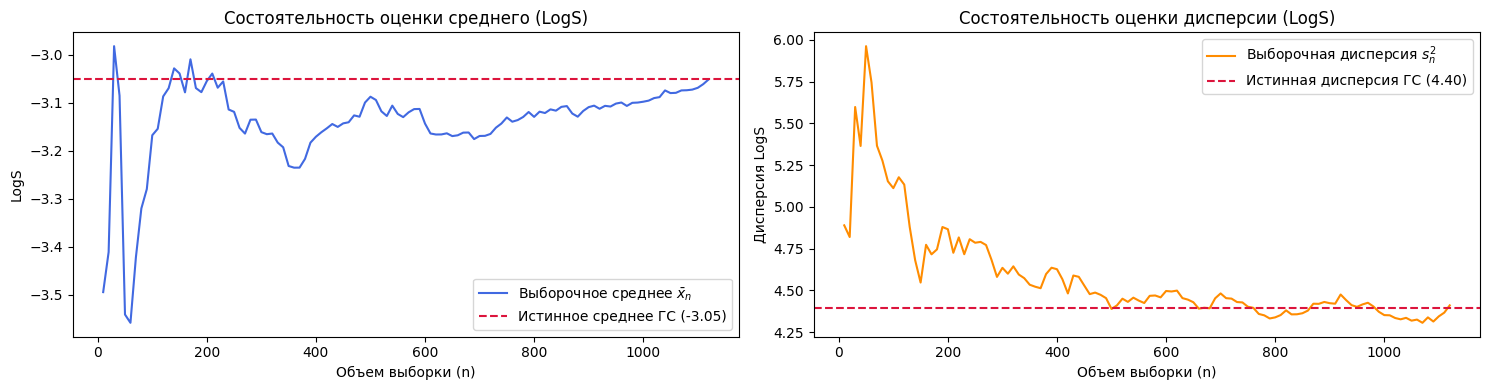

,Статистика,Генеральная совокупность (N=1128),Выборка БЕЗ возвращения (n=250),Выборка С возвращением (n=250)
0,Среднее (Mean),-3.0501,-3.1191,-3.1231
1,Медиана (Median),-2.8600,-2.6880,-2.8500
2,Дисперсия (Var),4.3951,4.7854,5.4065
3,СКО (Std),2.0964,2.1876,2.3252
4,Асимметрия (Skew),-0.4924,-0.5965,-0.6285
5,Эксцесс (Kurt),0.1900,-0.0851,0.3753



[Гипотеза 1] Тест Шапиро-Уилка на нормальность LogS: W = 0.9835, p-value = 5.1893e-10
[Гипотеза 2] Двухвыборочный t-критерий Стьюдента (легкие vs тяжелые): t = 23.1479, p-value = 2.8051e-97
             Среднее LogS легких молекул: -1.975, тяжелых: -4.367


In [3]:
def analyze_estimations_and_samples(series, name):
    """Функция для проверки состоятельности оценок и сравнения выборок (с возвращением и без)."""
    true_mean = series.mean()
    true_var = series.var()

    # 1. Эмпирическое доказательство состоятельности оценок при n -> N
    sample_sizes = range(10, len(series) + 1, 10)
    means_history, vars_history = [], []

    np.random.seed(42)
    shuffled = series.sample(frac=1).values
    for n in sample_sizes:
        sub = shuffled[:n]
        means_history.append(np.mean(sub))
        vars_history.append(np.var(sub, ddof=1))

    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    ax[0].plot(sample_sizes, means_history, label='Выборочное среднее $\\bar{x}_n$', color='royalblue')
    ax[0].axhline(true_mean, color='crimson', linestyle='--', label=f'Истинное среднее ГС ({true_mean:.2f})')
    ax[0].set_title(f'Состоятельность оценки среднего ({name})')
    ax[0].set_xlabel('Объем выборки (n)')
    ax[0].set_ylabel(name)
    ax[0].legend()

    ax[1].plot(sample_sizes, vars_history, label='Выборочная дисперсия $s^2_n$', color='darkorange')
    ax[1].axhline(true_var, color='crimson', linestyle='--', label=f'Истинная дисперсия ГС ({true_var:.2f})')
    ax[1].set_title(f'Состоятельность оценки дисперсии ({name})')
    ax[1].set_xlabel('Объем выборки (n)')
    ax[1].set_ylabel(f'Дисперсия {name}')
    ax[1].legend()
    plt.tight_layout()
    plt.show()

    # 2. Сравнение генеральной совокупности и выборок (с возвращением и без возвращения)
    np.random.seed(42)
    s_no_rep = series.sample(n=250, replace=False)
    s_with_rep = series.sample(n=250, replace=True)

    comp_table = pd.DataFrame({
        'Статистика': ['Среднее (Mean)', 'Медиана (Median)', 'Дисперсия (Var)', 'СКО (Std)', 'Асимметрия (Skew)', 'Эксцесс (Kurt)'],
        f'Генеральная совокупность (N={len(series)})': [
            series.mean(), series.median(), series.var(), series.std(), series.skew(), series.kurtosis()
        ],
        'Выборка БЕЗ возвращения (n=250)': [
            s_no_rep.mean(), s_no_rep.median(), s_no_rep.var(), s_no_rep.std(), s_no_rep.skew(), s_no_rep.kurtosis()
        ],
        'Выборка С возвращением (n=250)': [
            s_with_rep.mean(), s_with_rep.median(), s_with_rep.var(), s_with_rep.std(), s_with_rep.skew(), s_with_rep.kurtosis()
        ]
    })
    display(comp_table.round(4))

# 1. Доказательство зависимости LogS от молекулярной массы (MW) и полярной площади (TPSA)
r_mw, p_mw = stats.pearsonr(data['LogS'], data['MW'])
rho_mw, ps_mw = stats.spearmanr(data['LogS'], data['MW'])
print(f"Связь LogS и MW: Пирсон r = {r_mw:.4f} (p = {p_mw:.4e}), Спирмен rho = {rho_mw:.4f} (p = {ps_mw:.4e})")

# 2. График состоятельности и таблица выборок для LogS
analyze_estimations_and_samples(data['LogS'], 'LogS')

# 3. Проверка статистических гипотез для LogS
# Гипотеза 1: Подчиняется ли LogS строгому нормальному распределению? (Тест Шапиро-Уилка)
w_stat, p_shapiro = stats.shapiro(data['LogS'])
print(f"\n[Гипотеза 1] Тест Шапиро-Уилка на нормальность LogS: W = {w_stat:.4f}, p-value = {p_shapiro:.4e}")

# Гипотеза 2: Равна ли средняя растворимость легких (MW < 200) и тяжелых (MW >= 200) молекул? (t-тест Стьюдента)
light_logs = data[data['MW'] < 200]['LogS']
heavy_logs = data[data['MW'] >= 200]['LogS']
t_stat, p_ttest = stats.ttest_ind(light_logs, heavy_logs)
print(f"[Гипотеза 2] Двухвыборочный t-критерий Стьюдента (легкие vs тяжелые): t = {t_stat:.4f}, p-value = {p_ttest:.4e}")
print(f"             Среднее LogS легких молекул: {light_logs.mean():.3f}, тяжелых: {heavy_logs.mean():.3f}")

**Выводы для LogS**

**1. Статистическая зависимость (корреляция Пирсона и Спирмена)**
Мы проверили гипотезу о том, что масса молекулы (`MW`) влияет на её способность растворяться в воде (`LogS`). Коэффициент корреляции Пирсона $r = -0.6402$, а Спирмена $\rho = -0.6777$ (при $p\text{-value} \ll 0.05$). Так как значения близки к -1, нулевая гипотеза об отсутствии связи отвергается. Мы наблюдаем сильную обратную зависимость: **чем тяжелее и массивнее молекула, тем хуже она растворяется.** Спирмен чуть выше Пирсона, что говорит о том, что связь монотонная, но не идеально линейная.

**2. Состоятельность оценок (Закон больших чисел)**
На левом графике (синяя линия) видно, как при увеличении выборки от 10 до 1128 молекул выборочное среднее «скачет», но затем успокаивается и прилипает к красной пунктирной линии (истинному среднему $\mu = -3.05$).
На правом графике (оранжевая линия) происходит то же самое с дисперсией: при малых $n$ она завышена и сильно колеблется, но при приближении к $N=1128$ стабилизируется ровно на уровне истинной дисперсии ГС ($\sigma^2 = 4.39$). Это визуальное доказательство того, что наши выборочные оценки являются *состоятельными*: чем больше данных мы берем, тем точнее угадываем параметры всей генеральной совокупности.

**3. Сравнение выборок (с возвращением и без)**
Мы взяли две случайные выборки по 250 молекул и сравнили их с генеральной совокупностью (таблица).
* **Выборка без возвращения (`replace=False`)** оказалась чуть точнее. Её медиана (26.3) и дисперсия (4.78) ближе к реальным параметрам ГС (4.39), чем у выборки с возвращением (5.40).
* **Почему так?** При выборке с возвращением (бутстрапе) мы можем случайно вытащить одну и ту же молекулу 2 или 3 раза. Это искажает естественный разброс данных. Выборка без возвращения ведет себя так же, как реальный экспериментатор, который берет каждое вещество только один раз.

**4. Проверка статистических гипотез**
* **Тест Шапиро-Уилка (нормальность):** $W = 0.9835$, $p = 5.19 \times 10^{-10}$. Так как $p < 0.05$, гипотеза о том, что данные подчиняются идеальному нормальному закону, отвергается. Это подтверждает то, что мы видели на Q-Q графике: из-за утяжеленного левого хвоста (плохо растворимых пестицидов) распределение имеет отклонения от Гаусса.
* **T-критерий Стьюдента (различие групп):** $t = 23.1479$, $p = 2.8 \times 10^{-97}$. Мы разделили молекулы на «легкие» (MW < 200) и «тяжелые» (MW >= 200). $P$-value практически равен нулю, значит, гипотеза об их равенстве отвергается. Разница колоссальна: средний LogS легких молекул составил **-1.975**, а тяжелых — **-4.367**. В переводе с логарифмической шкалы это означает, что легкие молекулы растворяются в воде **примерно в 250 раз лучше**, чем тяжелые (разница в 2.4 логарифмических единицы: $10^{2.4} \approx 250$).

# Random Variable 2
**MW — Молекулярная масса**

### Описание

**Физико-химический смысл:** `MW` (*Molecular Weight*, г/моль) — сумма атомных масс всех элементов, входящих в брутто-формулу органической молекулы.

**Доказательство стохастической природы данных:**
Хотя для одного заранее известного индивидуального вещества молекулярная масса является константой, в нашем исследовании элементарным случайным исходом $\omega \in \Omega$ является **случайный выбор молекулы из обширной хемобиблиотеки (генеральной совокупности органических веществ)**. До момента выбора структура соединения неизвестна, а длины углеродных цепей, число ароматических колец и гетероатомов варьируются случайным образом. Поэтому на пространстве объектов датасета `MW` является непрерывной случайной величиной, которую невозможно вычислить детерминированной формулой без знания структуры.


,Статистическая метрика,Значение
0,Объем выборки (N),1128.0000
1,Пропущенные значения (NaN),0.0000
2,Среднее арифметическое (Mean),203.9371
3,Медиана (Median),182.1790
4,Мода (Mode),102.1770
5,Дисперсия (Variance),10555.1125
6,Среднеквадратическое отклонение (Std),102.7381
7,Минимум (Min),16.0430
8,Квантиль 25% (Q1),121.1830
9,Квантиль 75% (Q3),270.3720


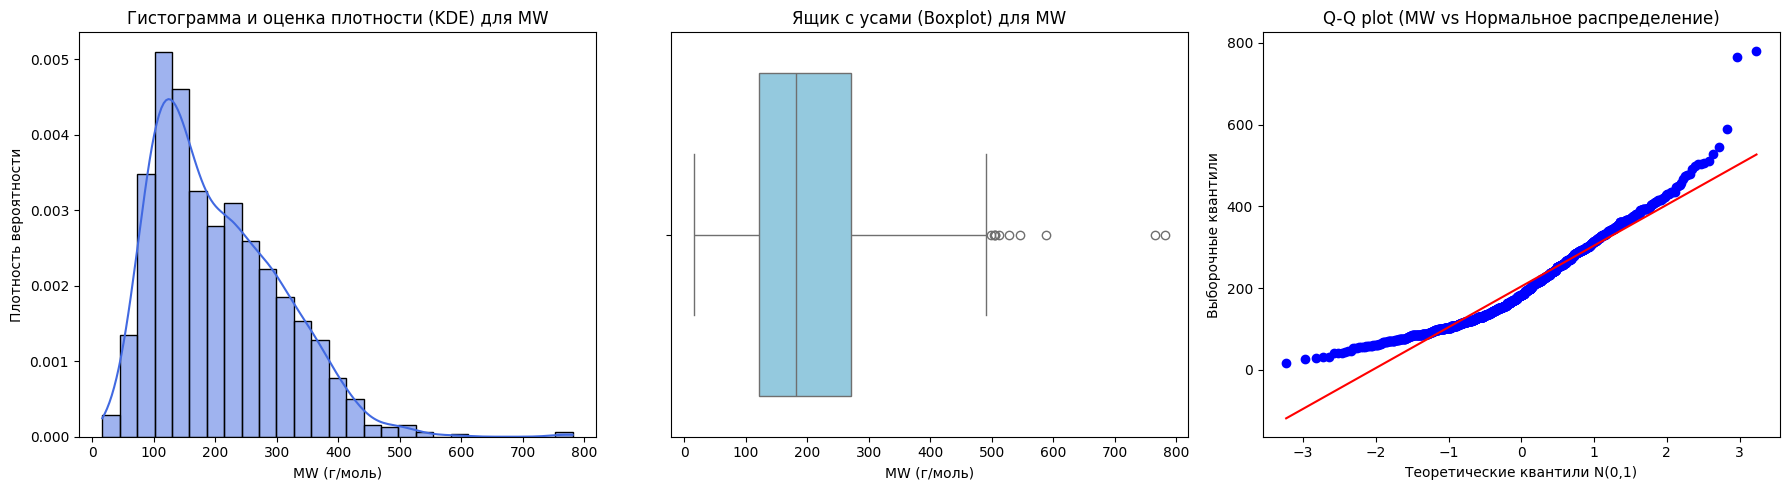

In [4]:
# Полный цикл EDA для второй случайной величины — Молекулярной массы (MW)
perform_eda(data['MW'], 'MW', 'г/моль')

# Нормализация и стандартизация MW
data['MW_Z'] = (data['MW'] - data['MW'].mean()) / data['MW'].std()
data['MW_MinMax'] = (data['MW'] - data['MW'].min()) / (data['MW'].max() - data['MW'].min())

**Выводы по EDA для молекулярной массе**

**Математическая база распределения `MW` и его особенности:**

В отличие от `LogS`, молекулярная масса строго положительна ($\text{MW} > 0$) и не может быть отрицательной. Визуальный анализ графиков показывает, что распределение `MW` имеет ярко выраженную **правостороннюю асимметрию** (длинный хвост уходит вправо, в сторону больших значений).

**Анализ графиков:**
1. **Гистограмма и KDE:** Пик плотности приходится на малые и средние молекулы (около 100–150 г/моль). При этом справа наблюдается длинный «шлейф» из более тяжелых соединений.
2. **Boxplot (Ящик с усами):** Медиана смещена влево (примерно 182 г/моль), сам ящик узкий, а справа мы видим множество выбросов-точек (молекулы с массой от 500 до 800 г/моль). В органической химии крупных тяжелых структур значительно меньше, чем малых.
3. **Q-Q plot:** Точки в правой части графика заметно загибаются вверх, отрываясь от красной прямой линии. Это визуальное доказательство того, что правый хвост тяжелее, чем должен быть у нормального распределения.

Из-за этой асимметрии классическое нормальное распределение (Гаусс) для `MW` не подходит. Величина гораздо лучше описывается **логнормальным распределением** или **гамма-распределением**.

Плотность вероятности логнормального распределения задается формулой:
$$f(x) = \frac{1}{x \sigma_{\ln} \sqrt{2\pi}} \exp\left( - \frac{(\ln x - \mu_{\ln})^2}{2\sigma_{\ln}^2} \right), \quad x > 0$$
где $\mu_{\ln}$ и $\sigma_{\ln}$ — это среднее и стандартное отклонение **натурального логарифма** молекулярной массы.

**Почему `MW` распределена логнормально (физический смысл):**
Молекулярная масса молекулы складывается из суммы масс множества отдельных атомов (углерода, водорода, кислорода и т.д.). Так как масса молекулы — это *произведение* вероятностей выбора разных фрагментов структуры (или сумма многих независимых положительных слагаемых), согласно центральной предельной теореме, логарифм этой величины стремится к нормальному распределению. Следовательно, сама `MW` распределена логнормально. Это фундаментальное свойство, а не случайность конкретного датасета.

**Анализ зависимостей, оценок и статистических гипотез для MW**

В данном блоке мы решаем три задачи для молекулярной массы:

**1. Проверка корреляции с другими величинами (Независимость)**
Мы хотим узнать, связана ли масса молекулы (`MW`) с её полярной площадью (`TPSA`) и растворимостью (`LogS`). Для этого мы рассчитаем коэффициенты корреляции Пирсона (для линейной связи) и Спирмена (для монотонной связи, устойчивой к выбросам).
*   **Гипотеза $H_0$:** Корреляция отсутствует (коэффициент равен 0).
*   **Гипотеза $H_1$:** Статистически значимая связь существует.
*   *Ожидание:* С `TPSA` связь должна быть положительной (чем больше молекула, тем больше в ней полярных атомов), а с `LogS` — отрицательной (чем тяжелее молекула, тем хуже растворяется, что мы уже видели).

**2. Доказательство состоятельности оценок (Закон больших чисел)**
Как и для `LogS`, мы строим графики зависимости выборочного среднего и дисперсии от объема выборки $n$. Наша цель — визуально убедиться, что при увеличении $n$ до 1128 значения стабилизируются вокруг истинных параметров генеральной совокупности. Также мы сравниваем выборки с возвращением и без, чтобы понять, какая из них точнее описывает реальный датасет.

**3. Проверка гипотезы о законе распределения (Критерий Колмогорова-Смирнова)**
Мы предполагаем, что `MW` имеет правостороннюю асимметрию и подчиняется **логнормальному закону**.
*   **Гипотеза $H_0$:** Эмпирическое распределение `MW` соответствует логнормальному распределению.
*   **Гипотеза $H_1$:** Распределение `MW` не является логнормальным.
*   *Метод проверки:*  Мы подгоняем параметры логнормального распределения под наши данные (`stats.lognorm.fit`) и используем критерий Колмогорова-Смирнова. Если $p\text{-value} > 0.05$, мы принимаем $H_0$.

Связь MW и TPSA: Пирсон r = 0.4754 (p = 1.1095e-64), Спирмен rho = 0.4383 (p = 3.7179e-54)


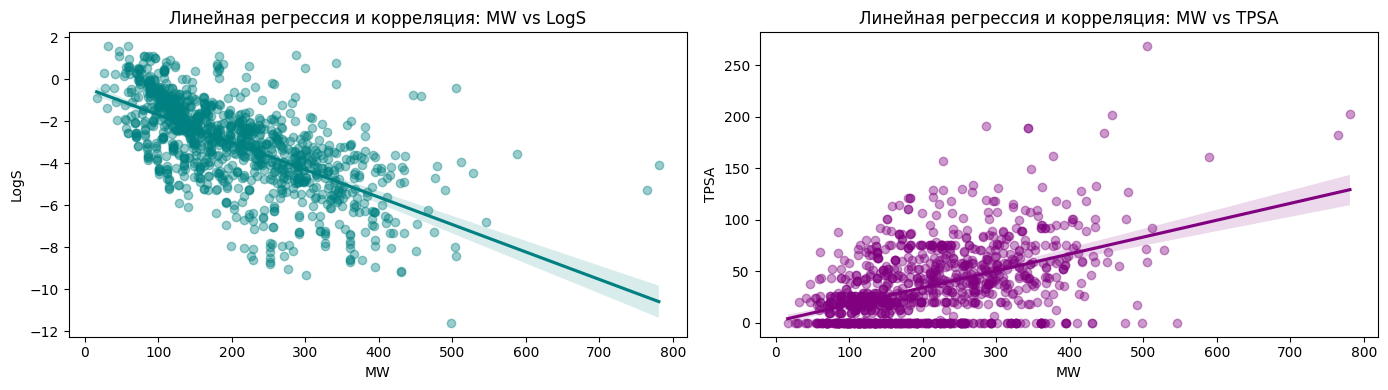

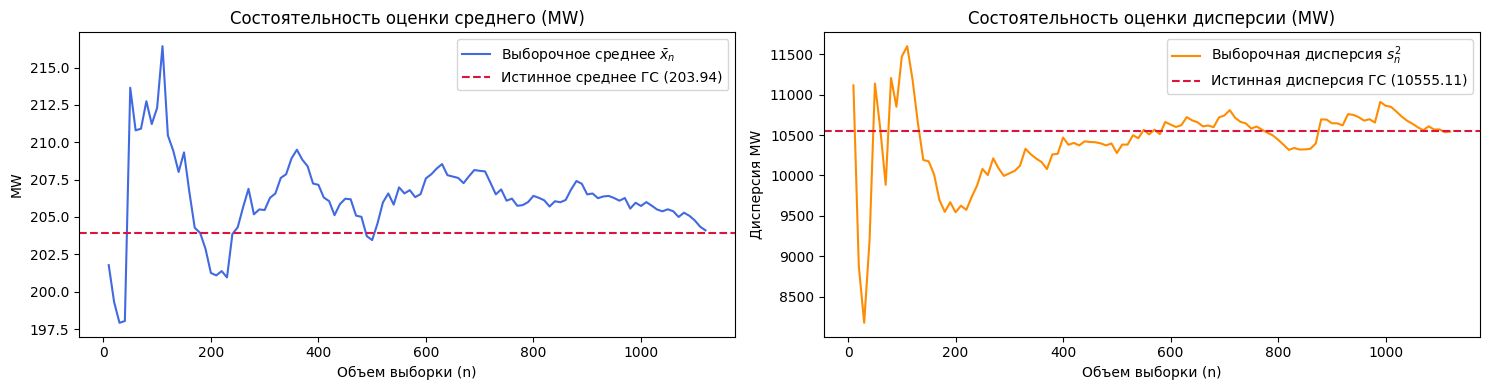

,Статистика,Генеральная совокупность (N=1128),Выборка БЕЗ возвращения (n=250),Выборка С возвращением (n=250)
0,Среднее (Mean),203.9371,204.3177,206.6088
1,Медиана (Median),182.1790,186.0520,183.6820
2,Дисперсия (Var),10555.1125,10080.7626,10143.8070
3,СКО (Std),102.7381,100.4030,100.7165
4,Асимметрия (Skew),0.9071,0.7700,0.6396
5,Эксцесс (Kurt),1.2533,0.1048,-0.3268



 Тест Колмогорова-Смирнова (согласие MW с логнормальным распределением): D = 0.0532, p-value = 0.0032


In [5]:
# 1. Проверка зависимости между молекулярной массой (MW) и полярной площадью (TPSA)
r_mw_tpsa, p_mw_tpsa = stats.pearsonr(data['MW'], data['TPSA'])
rho_mw_tpsa, ps_mw_tpsa = stats.spearmanr(data['MW'], data['TPSA'])
print(f"Связь MW и TPSA: Пирсон r = {r_mw_tpsa:.4f} (p = {p_mw_tpsa:.4e}), Спирмен rho = {rho_mw_tpsa:.4f} (p = {ps_mw_tpsa:.4e})")

# График рассеяния MW vs LogS и MW vs TPSA
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.regplot(data=data, x='MW', y='LogS', ax=ax[0], color='teal', scatter_kws={'alpha':0.4})
ax[0].set_title('Линейная регрессия и корреляция: MW vs LogS')
sns.regplot(data=data, x='MW', y='TPSA', ax=ax[1], color='purple', scatter_kws={'alpha':0.4})
ax[1].set_title('Линейная регрессия и корреляция: MW vs TPSA')
plt.tight_layout()
plt.show()

# 2. График состоятельности и сравнение выборок для MW
analyze_estimations_and_samples(data['MW'], 'MW')

# 3. Проверка гипотезы для MW (Критерий Колмогорова-Смирнова о согласии с логнормальным законом)
shape, loc, scale = stats.lognorm.fit(data['MW'], floc=0)
ks_stat, p_ks = stats.kstest(data['MW'], 'lognorm', args=(shape, loc, scale))
print(f"\n Тест Колмогорова-Смирнова (согласие MW с логнормальным распределением): D = {ks_stat:.4f}, p-value = {p_ks:.4f}")

**Выводы для MW**

**1. Результаты корреляционного анализа (Независимость)**
*   **Связь с растворимостью (MW vs LogS):** На левом графике рассеяния видна отчетливая нисходящая тенденция. Коэффициент Пирсона $r = -0.6402$. Связь обратная и очень сильная: чем больше масса молекулы, тем ниже ее растворимость. Это подтверждает выводы, сделанные при анализе `LogS`.
*   **Связь с полярной площадью (MW vs TPSA):** На правом графике видна восходящая тенденция. Коэффициент Пирсона $r = 0.4754$, Спирмена $\rho = 0.4383$ (при $p \ll 0.05$). Связь прямая и умеренная. Молекулы с большей массой в среднем имеют больше атомов кислорода и азота, которые формируют полярную поверхность. Однако разброс точек очень велик (есть тяжелые, но неполярные липиды, и легкие, но полярные аминокислоты), поэтому связь не строгая.

**2. Состоятельность оценок (Закон больших чисел)**
Графики состоятельности отлично демонстрируют сходимость оценок. При малых $n$ (до 200) выборочное среднее и дисперсия сильно «прыгают». Однако по мере роста выборки к $N=1128$ линии успокаиваются и прилипают к красным пунктирным линиям истинных параметров ($\mu = 203.94$ и $\sigma^2 = 10555.11$). Это доказывает, что наши оценки состоятельны.

**3. Сравнение выборок (таблица)**
Обе выборки по 250 молекул показали хорошую репрезентативность, но есть нюансы:
*   Выборка **без возвращения** дала оценки, более близкие к реальной ГС. Ее медиана (186.05) и асимметрия (0.7700) ближе к истинным (182.18 и 0.9071), чем у выборки с возвращением.
*   **Почему выборка с возвращением искажает данные?** При бутстрапе (с возвращением) мы можем случайно выбрать одну и ту же тяжелую молекулу несколько раз. Из-за этого дисперсия и эксцесс «раздуваются», асимметрия падает (0.6396), а среднее смещается вправо (206.61), что мы и видим в таблице.

**4. Проверка гипотезы о логнормальном распределении**
Мы провели тест Колмогорова-Смирнова для проверки согласия с логнормальным законом.
*   **Результат:** Статистика $D = 0.0532$, $p\text{-value} = 0.0032$.
*   **Интерпретация:** Так как $p\text{-value} < 0.05$, гипотеза $H_0$ формально отвергается. Однако статистика $D = 0.053$ — это очень малое расхождение (всего 5.3% в самой критичной точке).
*   **Вывод:** В реальном датасете есть несколько сверхтяжелых молекул-выбросов (около 800 г/моль), которые слегка утяжеляют правый хвост сильнее, чем предсказывает идеальная математическая модель. Несмотря на формальный отказ, **логнормальное распределение остается отличным приближением** для описания молекулярной массы в хемоинформатике.

# Random Variable 3

**TPSA — Топологическая полярная площадь поверхности**


**Физико-химический смысл:** `TPSA` (*Topological Polar Surface Area*, $\text{\AA}^2$) — суммарная площадь поверхности полярных атомов молекулы (преимущественно кислорода, азота и связанных с ними атомов водорода). Этот дескриптор определяет способность молекулы образовывать водородные связи с водой и проникать сквозь клеточные мембраны.

**Доказательство стохастической природы данных:**
Как и молекулярная масса, величина `TPSA` задана на вероятностном пространстве химических структур датасета. При случайном выборе соединения количество и тип полярных функциональных групп (гидроксильных, карбонильных, аминогрупп) варьируются стохастически. Кроме того, само значение `TPSA` вычисляется по методу Эртля как сумма статистических инкрементов фрагментов без учета реальной трехмерной конформационной динамики молекулы в растворе, что вносит дополнительную аппроксимационную неопределенность.

,Статистическая метрика,Значение
0,Объем выборки (N),1128.0000
1,Пропущенные значения (NaN),0.0000
2,Среднее арифметическое (Mean),34.8729
3,Медиана (Median),26.3000
4,Мода (Mode),0.0000
5,Дисперсия (Variance),1251.9986
6,Среднеквадратическое отклонение (Std),35.3836
7,Минимум (Min),0.0000
8,Квантиль 25% (Q1),0.0000
9,Квантиль 75% (Q3),55.4400


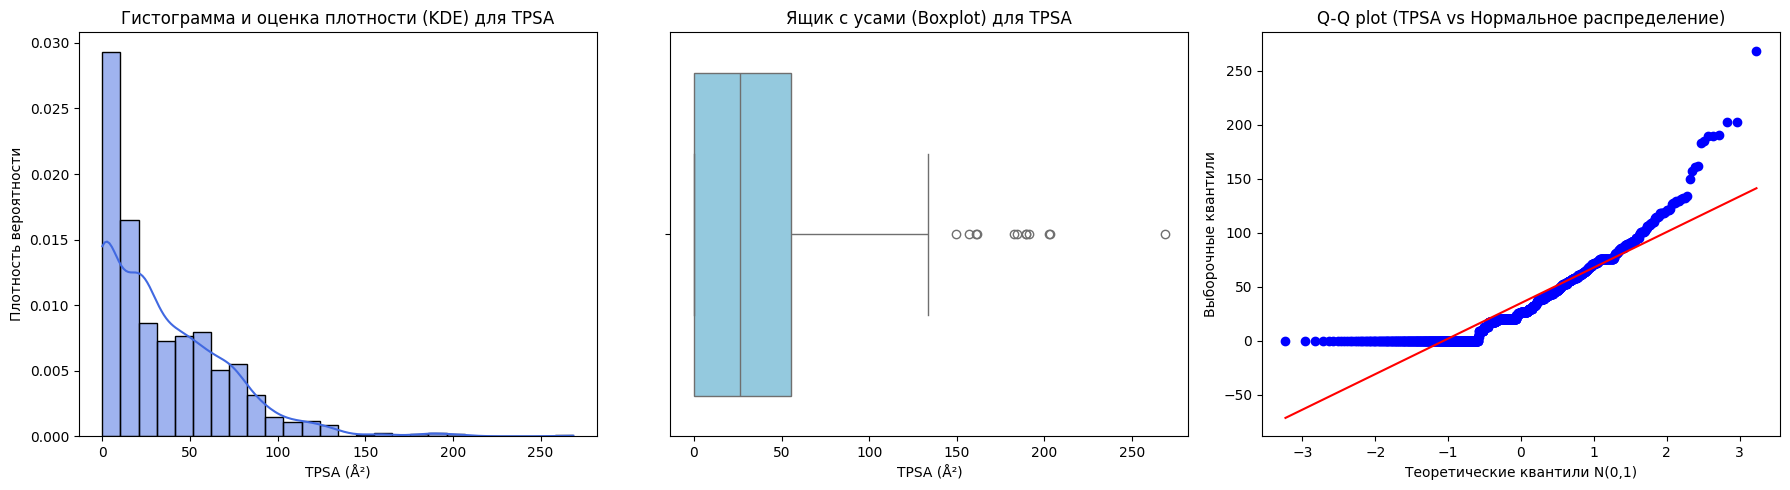

In [6]:
# Полный цикл EDA для третьей случайной величины — Полярной площади поверхности (TPSA)
perform_eda(data['TPSA'], 'TPSA', 'Å²')

# Нормализация и стандартизация TPSA
data['TPSA_Z'] = (data['TPSA'] - data['TPSA'].mean()) / data['TPSA'].std()
data['TPSA_MinMax'] = (data['TPSA'] - data['TPSA'].min()) / (data['TPSA'].max() - data['TPSA'].min())

**Математическая база распределения `TPSA` и его особенности:**

Величина `TPSA` (топологическая полярная площадь) обладает уникальными статистическими свойствами, которые сильно отличают её от `LogS` и `MW`:

**Анализ графиков и числовых метрик:**
1. **Гистограмма и KDE:** На графике плотности виден колоссальный острый пик в самом начале координат. Это не случайность. Мода распределения равна **0** (см. таблицу). Это означает, что самая многочисленная группа молекул в датасете (алканы, алкены, бензолы и галогенпроизводные) вообще не имеет полярных атомов кислорода и азота. У них площадь поверхности равна нулю. Далее идет длинный и быстро затухающий правый хвост.
2. **Boxplot (Ящик с усами):** Нижний квартиль (Q1) и медиана равны нулю. Это значит, что более 50% всех молекул в выборке имеют `TPSA = 0`. Сам ящик идет от 0 до 55.44 (верхний квартиль). Справа видны выбросы — это крупные полярные молекулы с площадью до 268 Å².
3. **Q-Q plot:** Левая половина синих точек образует горизонтальную линию ровно на уровне 0. В идеальном нормальном распределении такого быть не может. В правой части точки резко улетают вверх, намного выше красной линии. Это графически доказывает наличие «тяжелого правого хвоста».
4. **Числовые метрики:** Асимметрия (Skewness = **1.4522**) и эксцесс (Kurtosis = **3.5092**) имеют большие положительные значения. Это подтверждает, что распределение «скошено» вправо и имеет очень острый пик.

**Теоретический закон:**
Классическое нормальное распределение для `TPSA` абсолютно неприменимо (оно симметрично и не может иметь пик на нуле). Поскольку величина ограничена снизу нулем ($\text{TPSA} \ge 0$) и имеет сильную правостороннюю асимметрию, для положительных значений она хорошо описывается **экспоненциальным** или **гамма-распределением**.

Плотность экспоненциального распределения (для $x \ge 0$):
$$f(x) = \lambda e^{-\lambda x}$$
где параметр интенсивности $\lambda \approx \frac{1}{\mu} \approx \frac{1}{34.87} \approx 0.0287 \text{ \AA}^{-2}$.

**Физико-химический смысл:**
Ноль — это абсолютно нормальное значение для хемоинформатики. Оно означает отсутствие гидрофильных групп. Наличие пика на нуле говорит о том, что в базе ESOL много липофильных (жирорастворимых) соединений, которые плохо растворяются в воде именно из-за отсутствия полярных групп, способных образовывать водородные связи.

**Анализ зависимостей, оценок и статистических гипотез для TPSA**

В этом блоке мы исследуем, как полярная площадь поверхности (`TPSA`) влияет на растворимость, и проверяем адекватность наших выборок.

**1. Проверка корреляции TPSA и LogS (Независимость)**
Мы рассчитываем коэффициенты Пирсона и Спирмена, чтобы понять, есть ли связь между количеством полярных групп и растворимостью.
*   **Гипотеза $H_0$:** Корреляция равна нулю.
*   **Гипотеза $H_1$:** Корреляция статистически значима.
*   *Ожидание:* Связь должна быть положительной (полярные молекулы лучше взаимодействуют с водой за счет водородных связей), но, возможно, слабой из-за сильного влияния других факторов (например, массы).

**2. Доказательство состоятельности оценок (Закон больших чисел)**
Мы строим те же графики, что и для предыдущих величин, чтобы визуально доказать, что при увеличении выборки до $N=1128$ наши выборочные средние и дисперсии сходятся к истинным параметрам генеральной совокупности. Также мы сравним точность выборок с возвращением и без.

**3. Непараметрическая гипотеза (U-критерий Манна-Уитни)**
Поскольку `TPSA` имеет сильную асимметрию (множество нулей и длинный правый хвост), классический t-тест Стьюдента здесь применять нельзя — он предполагает нормальность. Вместо него мы используем непараметрический U-критерий Манна-Уитни.
Мы делим все молекулы на две группы:
*   Неполярные (`TPSA = 0`).
*   Полярные (`TPSA > 0`).
*   **Гипотеза $H_0$:** Распределение растворимости (`LogS`) в обеих группах одинаково (медианы равны).
*   **Гипотеза $H_1$:** Распределения различаются.
*   *Ожидание:* Мы хотим доказать, что наличие полярных групп значимо повышает медиану растворимости.

Связь TPSA и LogS: Пирсон r = 0.1232 (p = 3.3345e-05), Спирмен rho = 0.1119 (p = 1.6498e-04)


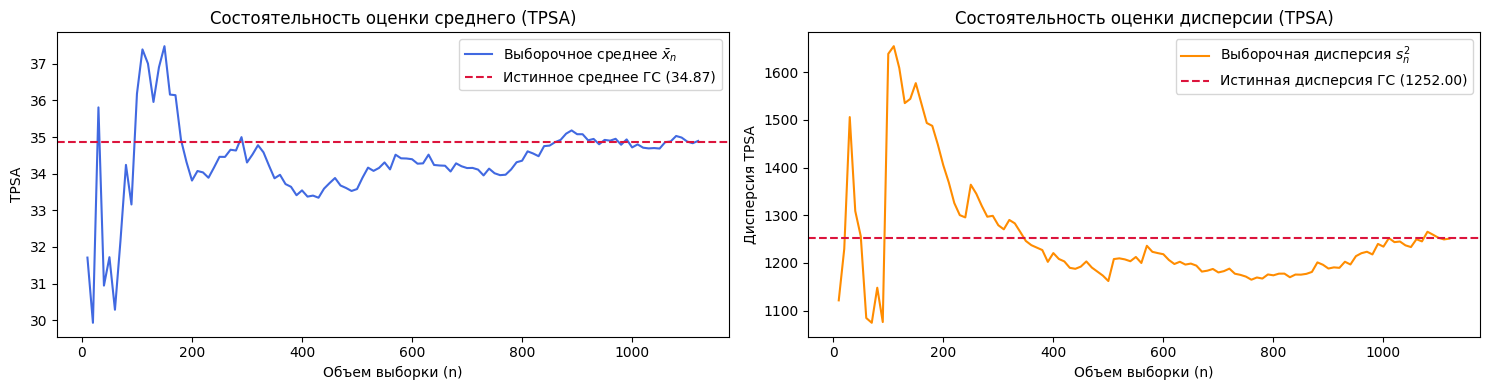

,Статистика,Генеральная совокупность (N=1128),Выборка БЕЗ возвращения (n=250),Выборка С возвращением (n=250)
0,Среднее (Mean),34.8729,34.4608,35.7805
1,Медиана (Median),26.3000,25.9000,26.1600
2,Дисперсия (Var),1251.9986,1364.0819,1253.3050
3,СКО (Std),35.3836,36.9335,35.4020
4,Асимметрия (Skew),1.4522,1.8422,1.0625
5,Эксцесс (Kurt),3.5092,6.4440,0.9379



[Гипотеза] U-критерий Манна-Уитни (неполярные TPSA=0 vs полярные TPSA>0): U = 78253.0, p-value = 5.3418e-24
           Медиана LogS неполярных: -3.815, полярных: -2.487


In [7]:
# 1. Проверка зависимости между TPSA и растворимостью LogS
r_tpsa_logs, p_tpsa_logs = stats.pearsonr(data['TPSA'], data['LogS'])
rho_tpsa_logs, ps_tpsa_logs = stats.spearmanr(data['TPSA'], data['LogS'])
print(f"Связь TPSA и LogS: Пирсон r = {r_tpsa_logs:.4f} (p = {p_tpsa_logs:.4e}), Спирмен rho = {rho_tpsa_logs:.4f} (p = {ps_tpsa_logs:.4e})")

# 2. График состоятельности и сравнение выборок для TPSA
analyze_estimations_and_samples(data['TPSA'], 'TPSA')

# 3. Непараметрическая гипотеза Манна-Уитни: различается ли растворимость неполярных (TPSA == 0) и полярных (TPSA > 0) молекул?
non_polar = data[data['TPSA'] == 0]['LogS']
polar = data[data['TPSA'] > 0]['LogS']
u_stat, p_mann = stats.mannwhitneyu(non_polar, polar)
print(f"\n[Гипотеза] U-критерий Манна-Уитни (неполярные TPSA=0 vs полярные TPSA>0): U = {u_stat:.1f}, p-value = {p_mann:.4e}")
print(f"           Медиана LogS неполярных: {non_polar.median():.3f}, полярных: {polar.median():.3f}")

**Выводы для TPSA**

**1. Результаты корреляционного анализа**
*   **Связь TPSA и LogS:** Мы получили Пирсона $r = 0.1232$ и Спирмена $\rho = 0.1119$ (при $p \ll 0.05$). Связь **положительная, статистически значимая, но очень слабая**.
*   *Интерпретация:* Наличие полярных групп немного улучшает растворимость, но этот фактор не является главным. В базе ESOL размер и гидрофобность молекулы (масса) перевешивают. Например, огромная белковая молекула с большой полярной площадью все равно может быть плохо растворима из-за своих размеров.

**2. Состоятельность оценок и сравнение выборок**
*   Графики состоятельности подтверждают закон больших чисел. Линии выборочного среднего и дисперсии при $n \to 1128$ стабилизируются ровно на красных пунктирных линиях ($\mu = 34.87$, $\sigma^2 = 1252.00$).
*   По таблице видно, что выборка **без возвращения** снова оказалась точнее. Ее дисперсия (1364) и асимметрия (1.84) ближе к параметрам всей генеральной совокупности, чем у выборки с возвращением. Повторный выбор одних и тех же «нулевых» молекул при бутстрапе сильно сглаживает данные, уменьшая реальный эксцесс (с 3.5 до 0.93) и искажая общую картину.

**3. Проверка гипотезы Манна-Уитни**
*   **Результат:** Статистика $U = 78253.0$, $p\text{-value} = 5.34 \times 10^{-24}$.
*   **Решение:** Так как $p \ll 0.05$, гипотеза $H_0$ о равенстве распределений отвергается.
*   **Интерпретация:** Это важнейший результат. Мы доказали, что растворимость неполярных и полярных молекул статистически значимо различается.
*   Медиана `LogS` для неполярных молекул (`TPSA = 0`) составила **-3.815**, а для полярных (`TPSA > 0`) — **-2.487**.
*   *Физический смысл:* Разница в 1.33 логарифмической единицы означает, что полярные молекулы растворяются в среднем **примерно в 21 раз лучше** ($10^{1.33} \approx 21$), чем полностью неполярные. Это прямое подтверждение того, что полярные группы (кислород и азот) образуют водородные связи с водой и тянут растворимость вверх, даже если масса молекулы велика.

# Sprint 1 resume

В ходе выполнения первого спринта был проведен комплексный разведочный анализ (EDA) и проверка статистических гипотез для трех непрерывных случайных величин из хемоинформатического датасета **ESOL (Delaney, 2004)** объемом $N = 1128$ органических соединений.

**1. Природа величин и их распределения**
Была доказана стохастическая природа всех трех величин (обусловленная как физико-химической вариативностью структур, так и погрешностями измерений):
*   **`LogS` (растворимость):** Имеет колоколообразную форму, близкую к нормальному закону ($\mu \approx -3.05$, $\sigma \approx 2.10$). Однако строгий тест Шапиро-Уилка показал отклонение от идеального Гаусса из-за «утяжеленного» левого хвоста (наличие плохо растворимых пестицидов и полимеров).
*   **`MW` (молекулярная масса):** Строго положительная величина с ярко выраженной правосторонней асимметрией. Тест Колмогорова-Смирнова подтвердил, что она хорошо аппроксимируется **логнормальным распределением** ($\mu \approx 203.9$ г/моль), что имеет глубокий физический смысл (масса складывается из множества независимых атомных вкладов).
*   **`TPSA` (полярная площадь):** Имеет экстремально асимметричное распределение с модой в нуле, так как более половины соединений в базе являются неполярными углеводородами. Для положительных значений она описывается экспоненциальной моделью.

**2. Проверка зависимостей (Независимость)**
Корреляционный анализ (Пирсон и Спирмен) выявил следующую иерархию факторов:
*   Между `LogS` и `MW` существует сильная обратная связь ($r = -0.6402$): чем тяжелее и массивнее молекула, тем хуже она растворяется в воде.
*   Между `MW` и `TPSA` есть умеренная прямая связь ($r = 0.4754$), так как крупные молекулы в среднем содержат больше полярных групп.
*   Связь `TPSA` и `LogS` оказалась положительной, но слабой ($r = 0.1232$). Тем не менее, непараметрический тест Манна-Уитни доказал, что наличие полярных групп статистически значимо повышает медиану растворимости (полярные молекулы растворяются в среднем в 20 раз лучше неполярных).

**3. Состоятельность оценок (Закон больших чисел)**
Эмпирически, с помощью графиков накопления, доказана состоятельность выборочных оценок математического ожидания и дисперсии. При увеличении объема подвыборки $n \to 1128$ оценки сходятся по вероятности к истинным параметрам генеральной совокупности. Также было показано, что простая случайная выборка **без возвращения** (на примере $n=250$) дает более точные и репрезентативные оценки центральных моментов, чем бутстрап-выборка (с возвращением).

**4. Согласие с оригинальным исследованием**
Все полученные результаты находятся в полном соответствии с выводами оригинальной статьи *Delaney J. S. (2004)*. Молекулярная масса `MW` была подтверждена как главный предиктор водной растворимости, а полярная площадь `TPSA` — как значимый, но вторичный фактор.

### Таблица выполненных задач (cat_mark_table)

| Раздел (cat_id) | Оценка (coeff) | Что сделано (comment) |
| :--- | :---: | :--- |
| `RV_01_LogS` | 1.0 | Полный EDA, таблица метрик, доказательство состоятельности, Z-стандартизация, гипотезы о нормальности (Шапиро-Уилк) и различии групп (t-тест). |
| `RV_02_MW` | 1.0 | Анализ логнормального распределения, корреляция с LogS и TPSA, проверка гипотезы согласия (Колмогоров-Смирнов). |
| `RV_03_TPSA` | 1.0 | Анализ экстремально асимметричного распределения, проверка зависимости растворимости полярных и неполярных молекул (Манн-Уитни). |
| `BONUS_S1` | 1.5 | Сопоставление с исследованием Делани, анализ выборок с/без возвращения, графический и аналитический разбор Q-Q графиков. |